In [1]:
import pulse_simulator as ps
import functools
import qiskit_dynamics as qk_d
import qiskit.providers.fake_provider as qk_fp
import numpy as np
import csv
import qiskit
import matplotlib.pyplot as plt
import scipy

/Users/epelaezc/Desktop/Research/pulse-simulator/.venv/lib/python3.11/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [2]:
backend = qk_fp.FakeManila()
units = 1e9
ns = units
dt = backend.configuration().dt * ns
print("dt: ", dt)

dt:  0.2222222222222222


In [40]:
N = 2

In [57]:
registers = [i for i in range(N)]
config_vars = ps.backend_simulation_vars(backend, rabi=False, units=units)

H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=config_vars,
    rotating_frame=False,
)

Hs_control = []
Hs_channels = []
for qubit in registers:
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel

In [110]:
Z = np.array([[1, 0], [0, -1]])
H_xtalk = qiskit.quantum_info.Operator(np.kron(Z, Z)) * 0.001

In [111]:
solver = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    static_dissipators=None,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    hamiltonian_channels=Hs_channels,
    channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
    dt=dt,
)
solver.model.evaluation_mode = 'dense'

In [112]:
default_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

file_name = "../pico-pulses/saved-pulses-2023-12-13/a_single_qubit_gateset_default.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    default_sim.set_pulse(name, qiskit_pulse)


In [126]:
robust_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

file_name = "../pico-pulses/saved-pulses-2023-12-13/a_single_qubit_gateset_R1e-3.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    robust_sim.set_pulse(name, qiskit_pulse)

In [134]:
robust_fidelities = []
default_fidelities = []

num_layers = [i for i in range(1, 11)]

for i in num_layers:
    qc = qiskit.QuantumCircuit(N)
    
    for _ in range(i):
        for q in range(N):
            qc.x(q)
        qc.barrier()
    
    expected = qiskit.quantum_info.Operator(qc)
    default_out = default_sim.simulate_circuit(qc)
    robust_out = robust_sim.simulate_circuit(qc)

    # print(np.round(default_out.data, 3))
    # print(np.round(robust_out.data, 3))
    # print("\n")

    robust_fidelities.append(qiskit.quantum_info.process_fidelity(expected, robust_out))
    default_fidelities.append(qiskit.quantum_info.process_fidelity(expected, default_out))

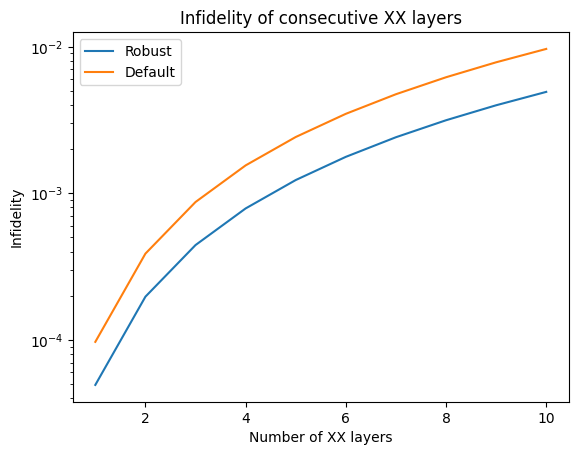

In [137]:
plt.plot(num_layers, 1 - np.array(robust_fidelities), label="Robust")
plt.plot(num_layers, 1 - np.array(default_fidelities), label="Default")
plt.yscale("log")
plt.xlabel("Number of XX layers")
plt.ylabel("Infidelity")
plt.title("Infidelity of consecutive XX layers")
plt.legend();